In [2]:
# Core libraries: pandas/numpy for data wrangling, matplotlib/seaborn for charts
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [3]:
# Default figure size and a clean grid style for every chart in this notebook
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")


<Figure size 1000x600 with 0 Axes>

In [5]:
# Load the raw dataset (76,000 store-product-day rows, Jan 2022 - Jan 2024)
df = pd.read_csv("/content/demand_forecasting.csv")

In [ ]:
# Preview the first rows to understand the columns and their values
df.head(5)

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [6]:
# Check each column's data type (Date is read as text at first)
df.dtypes

,0
Date,object
Store ID,object
Product ID,object
Category,object
Region,object
Inventory Level,int64
Units Sold,int64
Units Ordered,int64
Price,float64
Discount,int64


In [7]:
# Convert Date from text to a real datetime so we can extract year/month/day
df["Date"] = pd.to_datetime(df["Date"])

In [8]:
# Confirm Date is now datetime64
df.dtypes

,0
Date,datetime64[ns]
Store ID,object
Product ID,object
Category,object
Region,object
Inventory Level,int64
Units Sold,int64
Units Ordered,int64
Price,float64
Discount,int64


In [10]:
# Overview: row count, non-null counts and memory usage per column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                76000 non-null  datetime64[ns]
 1   Store ID            76000 non-null  object        
 2   Product ID          76000 non-null  object        
 3   Category            76000 non-null  object        
 4   Region              76000 non-null  object        
 5   Inventory Level     76000 non-null  int64         
 6   Units Sold          76000 non-null  int64         
 7   Units Ordered       76000 non-null  int64         
 8   Price               76000 non-null  float64       
 9   Discount            76000 non-null  int64         
 10  Weather Condition   76000 non-null  object        
 11  Promotion           76000 non-null  int64         
 12  Competitor Pricing  76000 non-null  float64       
 13  Seasonality         76000 non-null  object    

Checking the NULL values

In [13]:
# Total number of missing values across the whole dataset (0 = clean)
df.isna().sum().sum()

np.int64(0)

Checking Duplicates

In [16]:
# Number of fully duplicated rows (0 = no duplicates)
df.duplicated().sum()

np.int64(0)

In [17]:
# Summary statistics for numeric columns (mean, spread, min/max, quartiles)
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,76000,2023-01-15 12:00:00,2022-01-01 00:00:00,2022-07-09 18:00:00,2023-01-15 12:00:00,2023-07-24 06:00:00,2024-01-30 00:00:00,NaN
Inventory Level,76000.0,301.062842,0.0,136.0,227.0,408.0,2267.0,226.510161
Units Sold,76000.0,88.827316,0.0,58.0,84.0,114.0,426.0,43.994525
Units Ordered,76000.0,89.090645,0.0,0.0,0.0,121.0,1616.0,162.404627
Price,76000.0,67.726028,4.74,31.9975,64.5,95.83,228.03,39.377899
Discount,76000.0,9.087039,0.0,5.0,10.0,10.0,25.0,7.475781
Promotion,76000.0,0.328947,0.0,0.0,0.0,1.0,1.0,0.469834
Competitor Pricing,76000.0,69.454029,4.29,32.62,65.7,97.9325,261.22,40.943818
Epidemic,76000.0,0.2,0.0,0.0,0.0,0.0,1.0,0.400003
Demand,76000.0,104.317158,4.0,71.0,100.0,133.0,430.0,46.964801


In [18]:
# Summary of text columns: number of unique values and the most frequent one
df.describe(include="object").T

,count,unique,top,freq
Store ID,76000,5,S001,15200
Product ID,76000,20,P0001,3800
Category,76000,5,Groceries,30400
Region,76000,4,North,30400
Weather Condition,76000,4,Cloudy,24360
Seasonality,76000,4,Winter,21000


In [19]:
# Quick look at the data before adding new columns
df.head(2)

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229


Adding year and month Column

In [26]:
# Calendar features let us study seasonality by year and month
# Reload the original Date column and convert it to datetime
temp_df = pd.read_csv("/content/demand_forecasting.csv", usecols=["Date"])
df["Date"] = pd.to_datetime(temp_df["Date"])

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

In [27]:
# Check that Year and Month were added
df.head(2)

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand,Year,Month
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115,2022,1
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229,2022,1


In [28]:
# Day of month and weekday name, used to look for day-of-week patterns
df["Day"] = df["Date"].dt.day
df["Weekday"] = df["Date"].dt.day_name()

In [29]:
# Inspect the dataframe with the new date columns
df

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand,Year,Month,Day,Weekday
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115,2022,1,1,Saturday
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229,2022,1,1,Saturday
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157,2022,1,1,Saturday
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52,2022,1,1,Saturday
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59,2022,1,1,Saturday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5,Snowy,0,32.23,Winter,0,64,2024,1,30,Tuesday
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5,Snowy,0,40.73,Winter,0,137,2024,1,30,Tuesday
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10,Snowy,0,19.41,Winter,0,68,2024,1,30,Tuesday
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0,Snowy,0,143.71,Winter,0,84,2024,1,30,Tuesday


In [32]:
# Price the customer actually pays after the discount is applied
df["Discounted Price"] = df["Price"] * (1- df["Discount"] / 100 )

In [33]:
# Inspect the dataframe with the Discounted Price column
df

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,...,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand,Year,Month,Day,Weekday,Discounted Price
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,...,0,85.73,Winter,0,115,2022,1,1,Saturday,69.084
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,...,1,92.02,Winter,0,229,2022,1,1,Saturday,68.136
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,...,1,60.08,Winter,0,157,2022,1,1,Saturday,56.646
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,...,0,85.19,Winter,0,52,2022,1,1,Saturday,78.867
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,...,0,51.63,Winter,0,59,2022,1,1,Saturday,54.410
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5,...,0,32.23,Winter,0,64,2024,1,30,Tuesday,28.310
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5,...,0,40.73,Winter,0,137,2024,1,30,Tuesday,40.774
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10,...,0,19.41,Winter,0,68,2024,1,30,Tuesday,16.029
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0,...,0,143.71,Winter,0,84,2024,1,30,Tuesday,151.720


Sell through Rate

In [34]:
# Sell-through rate = share of stock that was actually sold (inventory efficiency KPI)
# Rows with Inventory Level = 0 give an undefined value, so they are excluded from the stats below
df["Sell Through Rate"] = df["Units Sold"] / df["Inventory Level"]

In [35]:
# Inspect the dataframe with the Sell Through Rate column
df

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,...,Competitor Pricing,Seasonality,Epidemic,Demand,Year,Month,Day,Weekday,Discounted Price,Sell Through Rate
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,...,85.73,Winter,0,115,2022,1,1,Saturday,69.084,0.523077
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,...,92.02,Winter,0,229,2022,1,1,Saturday,68.136,1.000000
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,...,60.08,Winter,0,157,2022,1,1,Saturday,56.646,0.461538
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,...,85.19,Winter,0,52,2022,1,1,Saturday,78.867,0.323741
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,...,51.63,Winter,0,59,2022,1,1,Saturday,54.410,0.427632
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5,...,32.23,Winter,0,64,2024,1,30,Tuesday,28.310,0.270386
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5,...,40.73,Winter,0,137,2024,1,30,Tuesday,40.774,0.839416
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10,...,19.41,Winter,0,68,2024,1,30,Tuesday,16.029,0.223350
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0,...,143.71,Winter,0,84,2024,1,30,Tuesday,151.720,0.464000


In [37]:
# Distribution of sell-through rate (higher = stock moves faster)
df["Sell Through Rate"].describe()

,Sell Through Rate
count,75594.000000
mean,0.437580
std,0.298007
min,0.003150
25%,0.190807
50%,0.350475
75%,0.642276
max,1.000000


Demand by Category

In [39]:
# Average, total and variability of demand per category, largest total first
df.groupby("Category")["Demand"].agg(["mean" , "sum" , "std"]).sort_values(by = "sum" , ascending =   False).reset_index()

,Category,mean,sum,std
0,Groceries,120.976447,3677684,48.362730
1,Clothing,112.619737,1369456,41.022968
2,Furniture,73.581140,1006590,32.336141
3,Toys,92.606955,985338,46.170390
4,Electronics,97.482018,889036,40.557859


In [41]:
# Average demand for each Region x Season combination
df.groupby(["Region" , "Seasonality" ])["Demand"].mean()

Region  Seasonality
East    Autumn         106.353297
        Spring         100.168478
        Summer         115.388315
        Winter         104.273571
North   Autumn         103.065797
        Spring          97.399457
        Summer         112.843750
        Winter         102.017738
South   Autumn         104.464560
        Spring         100.328804
        Summer         115.089946
        Winter         107.733095
West    Autumn         100.165385
        Spring          93.219293
        Summer         108.111141
        Winter         100.988810
Name: Demand, dtype: float64

In [42]:
# Average demand with (1) vs. without (0) a promotion, i.e. the promotion lift
df.groupby("Promotion")["Demand"].mean()

,Demand
Promotion,
0,95.026843
1,123.269400


Monthly Demand by Category

In [43]:
# Month x Category table of average demand, showing each category's seasonal peaks
pd.pivot_table(df , values= "Demand" , index ="Month" , columns= "Category" , aggfunc= "mean")

Category,Clothing,Electronics,Furniture,Groceries,Toys
Month,,,,,
1,126.997962,99.519022,75.690821,117.399457,94.242236
2,128.966518,84.184524,61.625992,103.522768,68.885204
3,105.835685,108.120968,84.015233,126.561694,128.273041
4,106.972917,85.916667,63.005556,105.111250,85.753571
5,108.650202,79.577957,56.036738,98.637903,71.756912
6,105.670833,106.922222,79.908333,147.772500,100.825000
7,107.838710,87.418011,66.156810,128.744355,74.366359
8,107.871976,109.733871,83.524194,149.875403,102.794931
9,105.118750,105.015278,81.854630,122.239167,102.722619


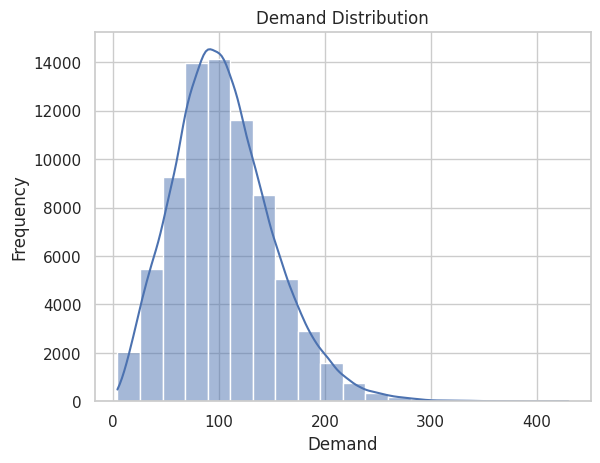

In [44]:
# Shape of the demand distribution (histogram + smoothed density curve)
sns.histplot(df["Demand"] , bins = 20 , kde = True)
plt.title("Demand Distribution")
plt.xlabel("Demand")
plt.ylabel("Frequency")
plt.show()

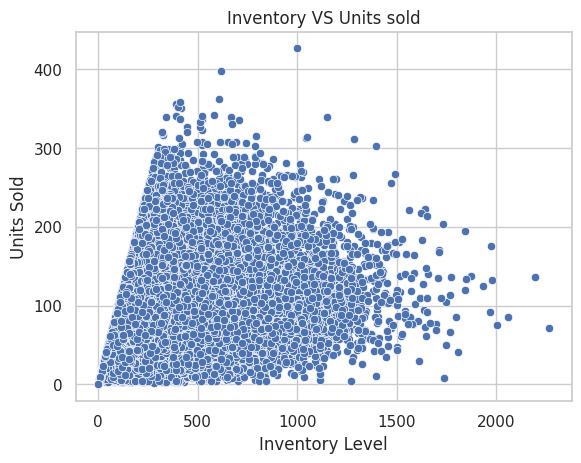

In [45]:
# Does carrying more inventory lead to more units sold?
sns.scatterplot(data = df , x = "Inventory Level" , y = "Units Sold")
plt.title("Inventory VS Units sold")
plt.xlabel("Inventory Level")
plt.ylabel("Units Sold")
plt.show()

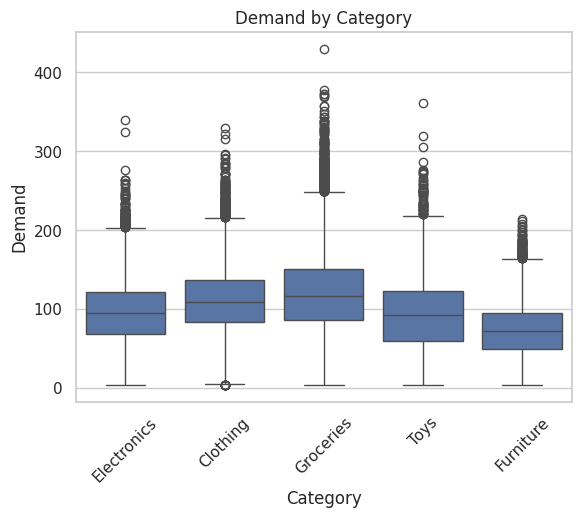

In [46]:
# Spread of demand within each category (median, quartiles, outliers)
sns.boxplot(data = df , x = "Category" , y = "Demand")
plt.xticks(rotation = 45)
plt.title("Demand by Category")
plt.xlabel("Category")
plt.show()

Demand by Weather Conditions

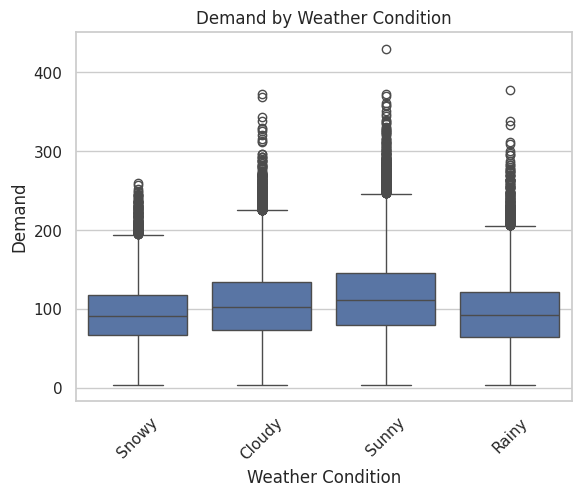

In [47]:
# Spread of demand under each weather condition
sns.boxplot(data = df , x= "Weather Condition" , y = "Demand")
plt.xticks(rotation = 45)
plt.title("Demand by Weather Condition")
plt.xlabel("Weather Condition")
plt.show()

# Time Series Analysis

In [48]:
# Inspect the full dataframe before the time-series analysis
df

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,...,Competitor Pricing,Seasonality,Epidemic,Demand,Year,Month,Day,Weekday,Discounted Price,Sell Through Rate
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,...,85.73,Winter,0,115,2022,1,1,Saturday,69.084,0.523077
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,...,92.02,Winter,0,229,2022,1,1,Saturday,68.136,1.000000
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,...,60.08,Winter,0,157,2022,1,1,Saturday,56.646,0.461538
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,...,85.19,Winter,0,52,2022,1,1,Saturday,78.867,0.323741
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,...,51.63,Winter,0,59,2022,1,1,Saturday,54.410,0.427632
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5,...,32.23,Winter,0,64,2024,1,30,Tuesday,28.310,0.270386
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5,...,40.73,Winter,0,137,2024,1,30,Tuesday,40.774,0.839416
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10,...,19.41,Winter,0,68,2024,1,30,Tuesday,16.029,0.223350
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0,...,143.71,Winter,0,84,2024,1,30,Tuesday,151.720,0.464000


Monthly demands of all the products in general


In [49]:
# Average demand per calendar month across all products, stores and years
monthly_demand = df.groupby("Month")["Demand"].mean()

In [50]:
# Show the monthly averages
monthly_demand

,Demand
Month,
1,106.040000
2,92.882500
3,113.613871
4,92.816667
5,86.521129
6,117.346000
7,101.561613
8,119.803387
9,107.431500


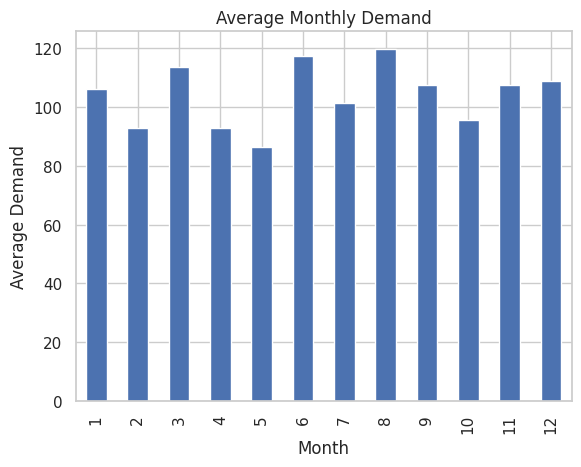

In [51]:
# Bar chart of average demand by month to show seasonality
monthly_demand.plot(kind = "bar" )
plt.title("Average Monthly Demand")
plt.xlabel("Month")
plt.ylabel("Average Demand")
plt.show()

In [52]:
# Total demand across all stores and products for each day
daily_demand = df.groupby("Date")["Demand"].sum()

In [53]:
# Show the daily totals
daily_demand

,Demand
Date,
2022-01-01,10060
2022-01-02,10814
2022-01-03,11317
2022-01-04,11469
2022-01-05,11724
...,...
2024-01-26,11182
2024-01-27,11540
2024-01-28,11440


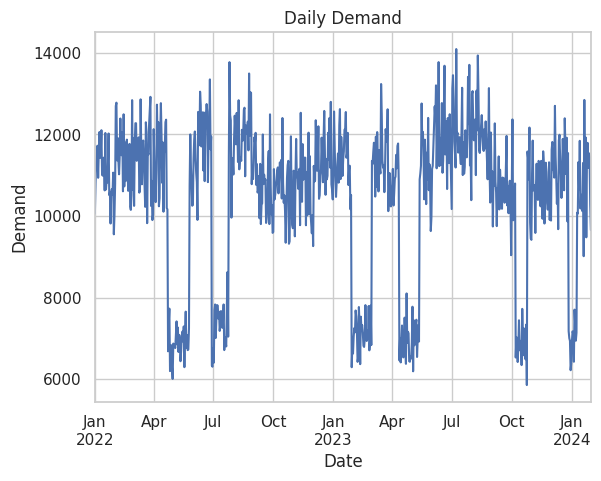

In [55]:
# Daily demand over time, to look for trend and shocks
daily_demand.plot()
plt.title("Daily Demand")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.show()

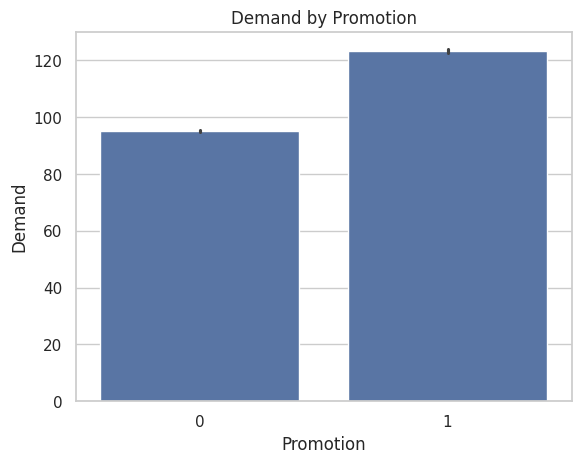

In [56]:
# Compare average demand with and without a promotion
sns.barplot(data = df , x="Promotion" , y = "Demand")
plt.title("Demand by Promotion")
plt.xlabel("Promotion")
plt.ylabel("Demand")
plt.show()

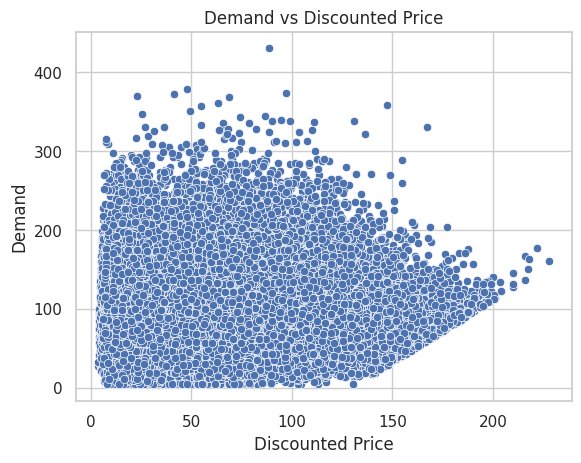

In [58]:
# Does a lower final price (after discount) increase demand?
sns.scatterplot(data= df , x="Discounted Price" , y= "Demand" )
plt.title("Demand vs Discounted Price")
plt.xlabel("Discounted Price")
plt.ylabel("Demand")
plt.show()

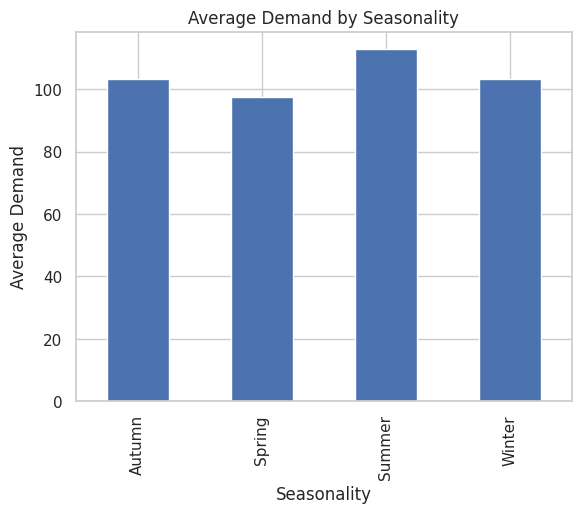

In [59]:
# Average demand per season
df.groupby("Seasonality")["Demand"].mean().plot(kind = "bar")
plt.title("Average Demand by Seasonality")
plt.xlabel("Seasonality")
plt.ylabel("Average Demand")
plt.show()

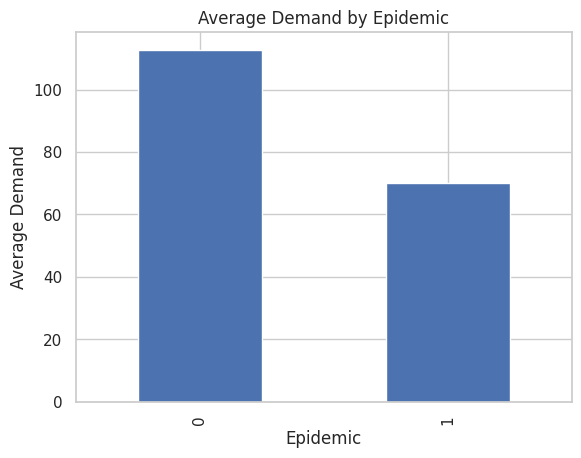

In [62]:
# Average demand during normal (0) vs. epidemic (1) periods
df.groupby("Epidemic")["Demand"].mean().plot(kind = "bar")
plt.title("Average Demand by Epidemic")
plt.xlabel("Epidemic")
plt.ylabel("Average Demand")
plt.show()